In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 07b — Step 4b: 3-month window context channels (round 4b)

**Question:** step 4 (year channels) gave the best accuracy so far, but its monthly maps hardly change
(test mIoU 0.69 in *every* month) — the 12-month statistics are identical for all months, so real change
inside the year can be smoothed away. Does a **3-month window** keep most of the gain while still following time?

| Run | = settings of | + change |
|---|---|---|
| `A_unet_v4b` | `A_unet_v4` | `FEATURES = "monthly+window3"` (mean / std of VV, VH over previous, current, next month) |
| `C_segformer_v4b` | `C_segformer_v4` | `FEATURES = "monthly+window3"` |

Same data as step 4 (`data_r3/`), shared code in `train_lib_r5.py`, no new preprocessing.
Window-channel statistics are saved once as `data_r3/norm_stats_window3.json` (new file).
`NUM_WORKERS = 0` (avoids the shared-memory crash). Finished runs are **skipped**, unfinished ones **resume**.
Compare in **05d_compare_r5.ipynb** (step 6 will also measure how much each model's monthly maps change).

## 1. Setup

In [2]:
import importlib, subprocess, sys
if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "-q",
                           "--no-warn-script-location", "segmentation-models-pytorch"])
sys.path.append(".")
import gc, json, torch
from pathlib import Path
import train_lib_r5 as tl
from train_lib_r5 import DEV
print("torch", torch.__version__, "| device:", DEV)

torch 2.9.1+cu128 | device: cuda


## 2. Experiment list

`BASE` = the settings used in 04a/b/c. Each experiment only lists what it changes (v4 = v2/v3 settings + year channels).
Comment out (`#`) any line you don't want to run now.

In [3]:
BASE = dict(
    DATA="data_r3", PRETRAINED=True, EPOCHS=40, WARMUP_EPOCHS=2, BATCH_SIZE=16, LR=3e-4,
    WEIGHT_DECAY=1e-4, PATIENCE=8, USE_CLASS_WEIGHTS=True, LOSS="dice", LABEL_SMOOTHING=0.0,
    NOISE_DB=1.0, MONTH_MIX=0.0, NUM_WORKERS=0, SEED=42, FEATURES="monthly",
)
LONGER_LOVASZ = dict(EPOCHS=60, PATIENCE=12, LOSS="lovasz")

WINDOW = dict(FEATURES="monthly+window3")

EXPERIMENTS = [
    # ---- step 4b: same as v4, but 3-month window instead of the whole year
    dict(RUN_NAME="C_segformer_v4b", GROUP="C_segformer_v4b", ARCH="segformer_mitb2",
         MODEL_NAME="SegFormer / MiT-B2 v4b (+3-month window)", **LONGER_LOVASZ, LR=6e-5, WARMUP_EPOCHS=5,
         WEIGHT_DECAY=0.01, NOISE_DB=2.0, MONTH_MIX=0.3, **WINDOW),
    dict(RUN_NAME="A_unet_v4b",      GROUP="A_unet_v4b",      ARCH="unet_resnet34",
         MODEL_NAME="U-Net / ResNet-34 v4b (+3-month window)",  **LONGER_LOVASZ, **WINDOW),
]
for e in EXPERIMENTS:
    print(f"{e['RUN_NAME']:18s} {e['ARCH']:24s} " + ", ".join(f"{k}={v}" for k, v in e.items()
          if k not in ("RUN_NAME", "GROUP", "ARCH", "MODEL_NAME") and BASE.get(k) != v))

C_segformer_v4b    segformer_mitb2          EPOCHS=60, PATIENCE=12, LOSS=lovasz, LR=6e-05, WARMUP_EPOCHS=5, WEIGHT_DECAY=0.01, NOISE_DB=2.0, MONTH_MIX=0.3, FEATURES=monthly+window3
A_unet_v4b         unet_resnet34            EPOCHS=60, PATIENCE=12, LOSS=lovasz, FEATURES=monthly+window3


## 3. Validation set (loaded once)
The context-channel statistics (`norm_stats_year.json` / `norm_stats_window3.json` in the data folder) are computed automatically by the first run that needs them, from the training patches only.

In [4]:
import shutil
_tmp, DATA, stats, index = tl.setup(dict(BASE, RUN_NAME="_tmp")); shutil.rmtree(_tmp)
val_ds = tl.EvalPatches(index[index.split == "val"].file, DATA, desc="loading val")
print("val regions:", sorted(index[index.split == "val"].region.unique()))
print("train patches:", (index.split == "train").sum(), "| val patches:", (index.split == "val").sum())

device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB


loading val:   0%|          | 0/128 [00:00<?, ?it/s]

val regions: ['bangkok', 'danube_delta', 'iowa', 'las_vegas', 'madrid', 'saskatchewan', 'serengeti', 'sudd_wetland']
train patches: 700 | val patches: 128


## 4. Run all experiments
For each experiment: setup → data → model → sanity check → training → curves → validation results.


C_segformer_v4b  —  SegFormer / MiT-B2 v4b (+3-month window)
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB


window3-channel stats:   0%|          | 0/700 [00:00<?, ?it/s]

train patches 700 | val samples 1536 (128 patches x 12 months)
24.7 M parameters | encoder weights: imagenet | loss: CE + lovasz | input channels: 7
step  0  loss 3.046
step 10  loss 1.055
step 20  loss 0.883
step 29  loss 0.804


epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

ep  0 | train 2.633 | val 2.495 | OA 0.494 | mIoU 0.224  *best* | 56s


epoch 1:   0%|          | 0/43 [00:00<?, ?it/s]

... (57 outputs left out)

epoch 30:   0%|          | 0/43 [00:00<?, ?it/s]

ep 30 | train 0.641 | val 1.430 | OA 0.768 | mIoU 0.548 | 53s


epoch 31:   0%|          | 0/43 [00:00<?, ?it/s]

ep 31 | train 0.640 | val 1.439 | OA 0.769 | mIoU 0.552 | 53s
Early stopping.
Done. Best val mIoU: 0.5702


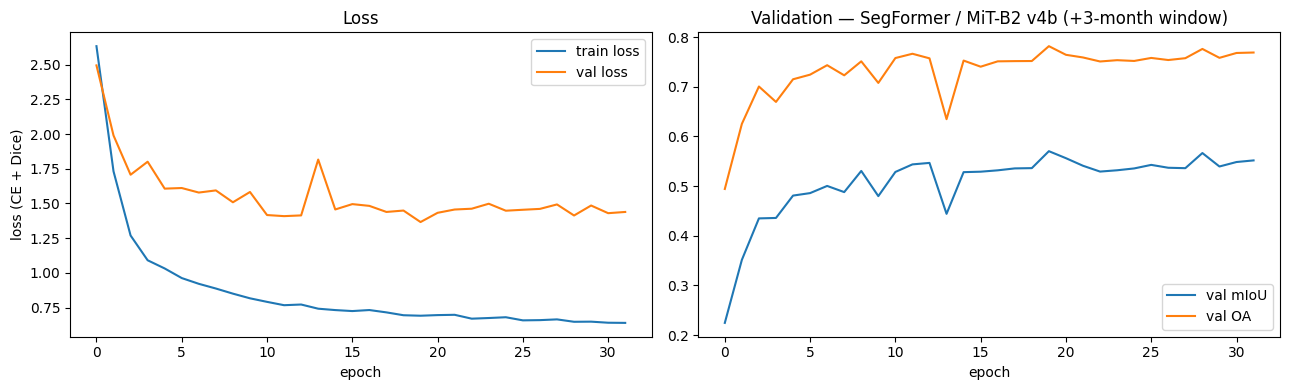

SegFormer / MiT-B2 v4b (+3-month window): val OA 0.782 | val mIoU 0.570 | 24.7 M params | 28.5 min


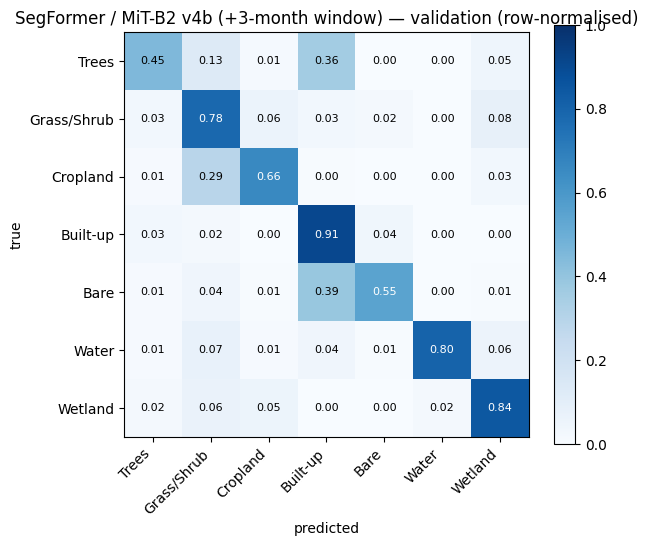

,IoU,F1
Trees,0.378,0.549
Grass/Shrub,0.604,0.753
Cropland,0.517,0.682
Built-up,0.772,0.871
Bare,0.268,0.423
Water,0.708,0.829
Wetland,0.744,0.853
mean,0.570,0.709



A_unet_v4b  —  U-Net / ResNet-34 v4b (+3-month window)
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB
train patches 700 | val samples 1536 (128 patches x 12 months)
24.4 M parameters | encoder weights: imagenet | loss: CE + lovasz | input channels: 7
step  0  loss 3.204
step 10  loss 1.507
step 20  loss 1.036
step 29  loss 0.813


epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

ep  0 | train 2.363 | val 2.246 | OA 0.549 | mIoU 0.284  *best* | 47s


epoch 1:   0%|          | 0/43 [00:00<?, ?it/s]

ep  1 | train 1.737 | val 2.403 | OA 0.446 | mIoU 0.238 | 47s


... (80 outputs left out)

epoch 42:   0%|          | 0/43 [00:00<?, ?it/s]

ep 42 | train 0.793 | val 1.577 | OA 0.713 | mIoU 0.499 | 47s


epoch 43:   0%|          | 0/43 [00:00<?, ?it/s]

ep 43 | train 0.774 | val 1.496 | OA 0.731 | mIoU 0.514 | 47s
Early stopping.
Done. Best val mIoU: 0.5166


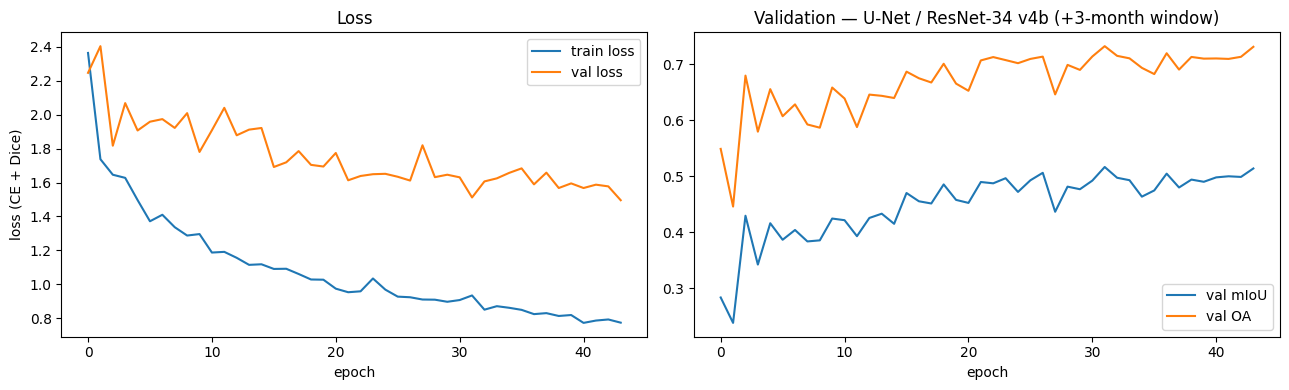

U-Net / ResNet-34 v4b (+3-month window): val OA 0.732 | val mIoU 0.517 | 24.4 M params | 34.6 min


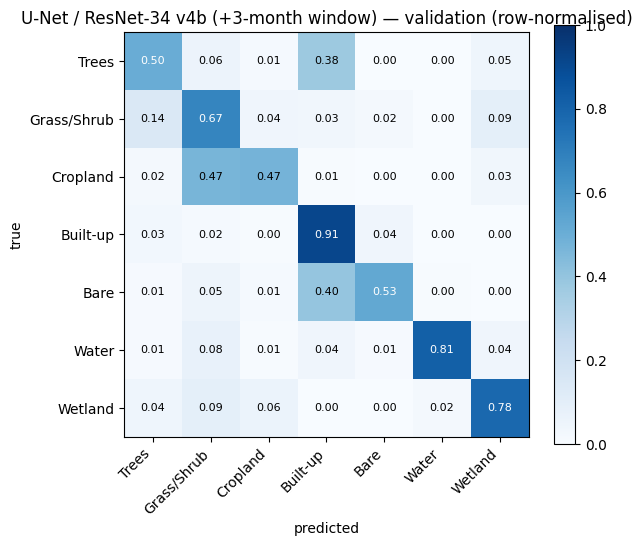

,IoU,F1
Trees,0.343,0.511
Grass/Shrub,0.495,0.662
Cropland,0.380,0.551
Built-up,0.767,0.868
Bare,0.245,0.394
Water,0.702,0.825
Wetland,0.684,0.812
mean,0.517,0.660


In [5]:
summary = []
for exp in EXPERIMENTS:
    CFG = dict(BASE, **exp)
    RUN = Path("runs") / CFG["RUN_NAME"]
    print("\n" + "=" * 90 + f"\n{CFG['RUN_NAME']}  —  {CFG['MODEL_NAME']}\n" + "=" * 90)
    if (RUN / "metrics.json").exists():
        m = json.load(open(RUN / "metrics.json"))
        print(f"already finished -> skipped (val mIoU {m['val_miou']:.3f})")
        summary.append(m); continue

    RUN, DATA, stats, index = tl.setup(CFG)
    train_dl, val_dl = tl.make_loaders(CFG, DATA, stats, index, val_ds=val_ds)
    model, CFG["WEIGHTS_USED"] = tl.build_pretrained(CFG["ARCH"], CFG["PRETRAINED"], tl.in_channels_of(CFG))
    json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
    model = model.to(DEV)
    loss_fn = tl.make_loss(CFG, stats)
    print(f"{tl.count_params(model):.1f} M parameters | encoder weights: {CFG['WEIGHTS_USED']} | loss: CE + {CFG['LOSS']} | input channels: {tl.in_channels_of(CFG)}")
    if not (RUN / "last.pth").exists():
        tl.overfit_one_batch(model, loss_fn, train_dl, steps=30, lr=CFG["LR"] * 3)

    tl.train(model, CFG, RUN, train_dl, val_dl, loss_fn)
    tl.plot_curves(RUN, CFG["MODEL_NAME"])
    display(tl.final_validation(model, CFG, RUN, val_dl))
    summary.append(json.load(open(RUN / "metrics.json")))

    del model, train_dl; gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()

## 5. Summary of this notebook's runs

In [7]:
import pandas as pd
tab = pd.DataFrame([{"run": m["run"], "val OA": m["val_oa"], "val mIoU": m["val_miou"],
                     "best epoch": m["best_epoch"], "epochs": m["epochs_run"], "min": m["train_minutes"]}
                    for m in summary]).set_index("run").sort_values("val mIoU", ascending=False)
display(tab)
print("Now run 05d_compare_r5.ipynb to compare with all earlier runs on the same validation and test sets.")

,val OA,val mIoU,best epoch,epochs,min
run,,,,,
C_segformer_v4b,0.7817,0.5702,19,32,28.5
A_unet_v4b,0.7323,0.5166,31,44,34.6


Now run 05d_compare_r5.ipynb to compare with all earlier runs on the same validation and test sets.


## 6. Save results

In [ ]:
import shutil
for m in summary:
    shutil.make_archive(f"{m['run']}_results", "zip", Path("runs") / m["run"])
    print("zipped:", f"{m['run']}_results.zip")